In [2]:
import pandas as pd

In [3]:
df=pd.read_csv("hypothesis.csv")

In [4]:
df

,Customer_ID,Campaign_Group,Age,Gender,Website_Visits,Session_Minutes,Purchase_Made,Order_Value_INR,Satisfaction_Before,Satisfaction_After
0,CUST0001,Social Media,25,Male,7,13.7,0,0.00,3,3
1,CUST0002,Email,26,Female,9,18.6,0,0.00,3,3
2,CUST0003,Social Media,56,Female,6,7.6,0,0.00,3,3
3,CUST0004,Social Media,50,Male,6,13.9,0,0.00,3,3
4,CUST0005,Control,30,Female,4,3.5,0,0.00,3,3
...,...,...,...,...,...,...,...,...,...,...
1195,CUST1196,Control,48,Female,6,4.1,0,0.00,4,3
1196,CUST1197,Control,48,Male,9,3.1,0,0.00,5,5
1197,CUST1198,Email,25,Female,6,10.8,1,250.55,4,5
1198,CUST1199,Control,31,Male,5,10.2,0,0.00,4,4


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Customer_ID          1200 non-null   object 
 1   Campaign_Group       1200 non-null   object 
 2   Age                  1200 non-null   int64  
 3   Gender               1200 non-null   object 
 4   Website_Visits       1200 non-null   int64  
 5   Session_Minutes      1200 non-null   float64
 6   Purchase_Made        1200 non-null   int64  
 7   Order_Value_INR      1200 non-null   float64
 8   Satisfaction_Before  1200 non-null   int64  
 9   Satisfaction_After   1200 non-null   int64  
dtypes: float64(2), int64(5), object(3)
memory usage: 93.9+ KB


In [6]:
df.isnull().sum()

Customer_ID            0
Campaign_Group         0
Age                    0
Gender                 0
Website_Visits         0
Session_Minutes        0
Purchase_Made          0
Order_Value_INR        0
Satisfaction_Before    0
Satisfaction_After     0
dtype: int64

In [7]:
df["Customer_ID"].value_counts()

Customer_ID
CUST0001    1
CUST0807    1
CUST0805    1
CUST0804    1
CUST0803    1
           ..
CUST0400    1
CUST0399    1
CUST0398    1
CUST0397    1
CUST1200    1
Name: count, Length: 1200, dtype: int64

In [8]:
df.describe(include="object")

,Customer_ID,Campaign_Group,Gender
count,1200,1200,1200
unique,1200,3,3
top,CUST0001,Control,Male
freq,1,409,610


In [9]:
df["Order_Value_INR"]=df["Order_Value_INR"].astype("int64")

In [10]:
df

,Customer_ID,Campaign_Group,Age,Gender,Website_Visits,Session_Minutes,Purchase_Made,Order_Value_INR,Satisfaction_Before,Satisfaction_After
0,CUST0001,Social Media,25,Male,7,13.7,0,0,3,3
1,CUST0002,Email,26,Female,9,18.6,0,0,3,3
2,CUST0003,Social Media,56,Female,6,7.6,0,0,3,3
3,CUST0004,Social Media,50,Male,6,13.9,0,0,3,3
4,CUST0005,Control,30,Female,4,3.5,0,0,3,3
...,...,...,...,...,...,...,...,...,...,...
1195,CUST1196,Control,48,Female,6,4.1,0,0,4,3
1196,CUST1197,Control,48,Male,9,3.1,0,0,5,5
1197,CUST1198,Email,25,Female,6,10.8,1,250,4,5
1198,CUST1199,Control,31,Male,5,10.2,0,0,4,4


In [11]:
for col in df.columns:
    if df[col].nunique()<20:
        print(df[col].value_counts())
        print("--"*50)

Campaign_Group
Control         409
Social Media    404
Email           387
Name: count, dtype: int64
----------------------------------------------------------------------------------------------------
Gender
Male      610
Female    557
Other      33
Name: count, dtype: int64
----------------------------------------------------------------------------------------------------
Website_Visits
6     209
5     204
7     190
4     167
8     111
3     103
9      71
10     47
2      46
11     23
1      11
12      9
13      5
14      3
15      1
Name: count, dtype: int64
----------------------------------------------------------------------------------------------------
Purchase_Made
0    910
1    290
Name: count, dtype: int64
----------------------------------------------------------------------------------------------------
Satisfaction_Before
3    500
4    355
2    227
5     87
1     31
Name: count, dtype: int64
--------------------------------------------------------------------------------

In [12]:
df["Session_Minutes"] = df["Session_Minutes"].astype(int)

In [13]:
df["Session_Minutes"]

0       13
1       18
2        7
3       13
4        3
        ..
1195     4
1196     3
1197    10
1198    10
1199     5
Name: Session_Minutes, Length: 1200, dtype: int32

In [14]:
df[df.duplicated()].shape

(0, 10)

In [15]:
df.describe()

,Age,Website_Visits,Session_Minutes,Purchase_Made,Order_Value_INR,Satisfaction_Before,Satisfaction_After
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.00000,1200.000000,1200.000000
mean,33.661667,5.970000,7.595000,0.241667,163.58750,3.200000,3.429167
std,8.808624,2.283297,5.242507,0.428272,304.21103,0.915987,1.142835
min,18.000000,1.000000,1.000000,0.000000,0.00000,1.000000,1.000000
25%,27.000000,4.000000,4.000000,0.000000,0.00000,3.000000,3.000000
50%,34.000000,6.000000,7.000000,0.000000,0.00000,3.000000,3.000000
75%,39.000000,7.000000,10.000000,0.000000,0.00000,4.000000,4.000000
max,60.000000,15.000000,35.000000,1.000000,1241.00000,5.000000,5.000000


In [16]:
# Filter only customers who purchased
buyers = df[df["Purchase_Made"] == 1]

# Descriptive statistics
buyers["Order_Value_INR"].describe()

count     290.000000
mean      676.913793
std       187.795063
min       189.000000
25%       545.750000
50%       677.000000
75%       811.500000
max      1241.000000
Name: Order_Value_INR, dtype: float64

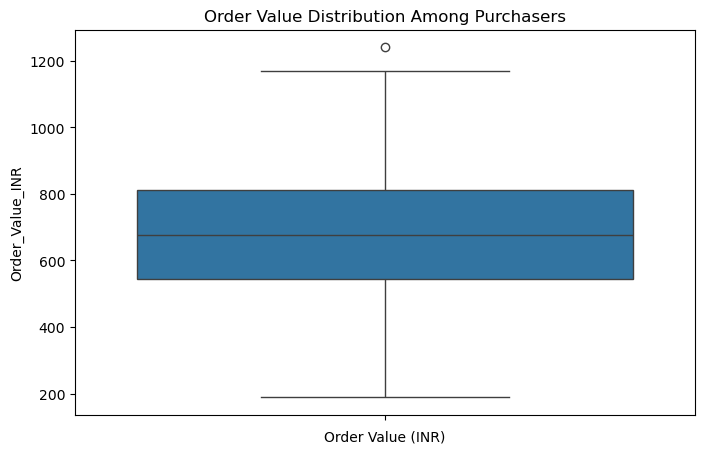

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 5))

sns.boxplot(y=buyers["Order_Value_INR"])

plt.title("Order Value Distribution Among Purchasers")
plt.xlabel("Order Value (INR)")

plt.show()

In [18]:
#remove outliners
df = df[df["Order_Value_INR"] <= 1200]

In [19]:
df.describe()

,Age,Website_Visits,Session_Minutes,Purchase_Made,Order_Value_INR,Satisfaction_Before,Satisfaction_After
count,1199.000000,1199.000000,1199.000000,1199.000000,1199.000000,1199.000000,1199.000000
mean,33.667223,5.968307,7.585488,0.241034,162.688907,3.199333,3.428691
std,8.810196,2.283496,5.234325,0.427889,302.740531,0.916078,1.143192
min,18.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000
25%,27.000000,4.000000,4.000000,0.000000,0.000000,3.000000,3.000000
50%,34.000000,6.000000,7.000000,0.000000,0.000000,3.000000,3.000000
75%,39.000000,7.000000,10.000000,0.000000,0.000000,4.000000,4.000000
max,60.000000,15.000000,35.000000,1.000000,1171.000000,5.000000,5.000000


In [20]:
# Descriptive statistics
df["Order_Value_INR"].describe()

count    1199.000000
mean      162.688907
std       302.740531
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max      1171.000000
Name: Order_Value_INR, dtype: float64

In [21]:
df["Purchase_Made"].value_counts(normalize=True) * 100

Purchase_Made
0    75.89658
1    24.10342
Name: proportion, dtype: float64

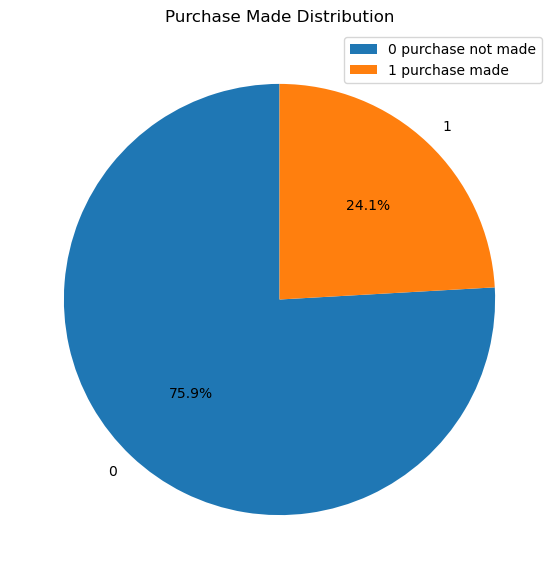

In [22]:
import matplotlib.pyplot as plt

purchase_percentage = df["Purchase_Made"].value_counts(normalize=True) * 100

plt.figure(figsize=(7, 7))

plt.pie(
    purchase_percentage,
    labels=purchase_percentage.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.legend(["0 purchase not made","1 purchase made"])

plt.title("Purchase Made Distribution")
plt.show()

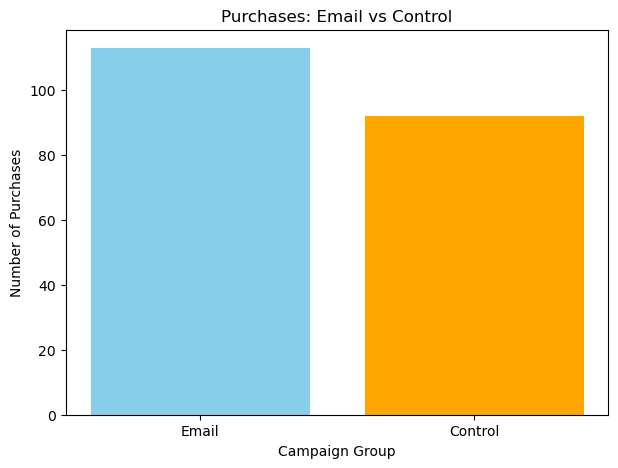

In [23]:
import matplotlib.pyplot as plt

filtered_df = df[df["Campaign_Group"].isin(["Email", "Control"])]

purchase_counts = (
    filtered_df[filtered_df["Purchase_Made"] == 1]
    ["Campaign_Group"].value_counts()
    .reindex(["Email", "Control"], fill_value=0)
)

plt.figure(figsize=(7, 5))

plt.bar(
    purchase_counts.index,
    purchase_counts.values,
    color=["skyblue", "orange"]
)

plt.title("Purchases: Email vs Control")
plt.xlabel("Campaign Group")
plt.ylabel("Number of Purchases")

plt.show()

In [27]:
a = df[df["Purchase_Made"] == 1]["Campaign_Group"]
a.value_counts()

Campaign_Group
Email           113
Control          92
Social Media     84
Name: count, dtype: int64

In [29]:
groups = df[
    (df["Campaign_Group"].isin(["Email", "Control"])) &
    (df["Purchase_Made"] == 1)
]

groups.groupby("Campaign_Group")["Order_Value_INR"].agg(
    ["count", "mean", "std"]
)

,count,mean,std
Campaign_Group,,,
Control,92,633.597826,191.425368
Email,113,716.230088,176.086272


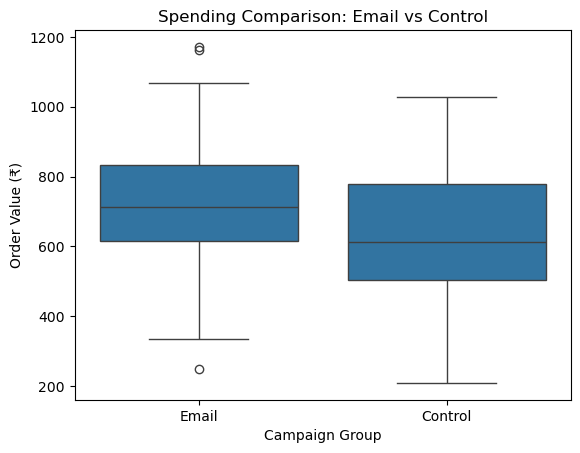

In [30]:
import seaborn as sns

sns.boxplot(data=groups, x="Campaign_Group", y="Order_Value_INR")

plt.title("Spending Comparison: Email vs Control")
plt.xlabel("Campaign Group")
plt.ylabel("Order Value (₹)")
plt.show()

In [31]:
from scipy.stats import ttest_ind

control = groups[groups["Campaign_Group"] == "Control"]["Order_Value_INR"]
email = groups[groups["Campaign_Group"] == "Email"]["Order_Value_INR"]

t_stat, p_value = ttest_ind(email, control, equal_var=False)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 3.185965250646825
P-value: 0.0016903083732236809
